# Phase E: Failure attribution — perception, planning or control?

Each collision is assigned a **likely primary cause** from the evidence gathered in the earlier phases. Run `planning_analysis.ipynb` and `control_analysis.ipynb` first: this notebook reads their per-collision tables.

| Evidence | Source | Meaning |
|---|---|---|
| **Perception** | struck actor detection (Phase B) | Was a TF++ box on the actor it hit 1.5 to 0.5 s before impact? |
| **Planning** | retrospective plan check (Phase C) | Would the plan, followed exactly, have run into the actor's real future path? |
| **Control** | tracking checks (Phase D) | Did the car follow its own plan (cross-track error) and the speed rule? |

**Rules**, applied in order:

1. **External / uncertain.** The ego was stopped, or was hit from behind.
2. **Perception.** The actor was in range but boxed less than 50% of the time in the decision window (1.5 to 0.5 s before impact). For static objects: no TF++ box within 2.5 m one second before impact.
3. **Control.** The car drifted more than 1 m off its own plan, or the throttle/brake did not match the rule, **and** no conflict was visible yet 1 s before impact. A visible conflict means either check from Phase C flagged it: TF++'s plan against the actor's real future, or TF++'s plan against its own tracked boxes.
4. **Planning.** The actor was boxed, the car followed its plan, and a conflict was visible at least 1 s before impact. The planner kept a plan that ran into a visible actor.
5. **Mixed.** As in 4, but perception was only partial (boxed 50–80% of the time), or the car also drifted from its plan.
6. **Planning, late conflict.** The actor was boxed and the car followed its plans, but the conflict only became visible in the last second.
   - TF++'s planned path reaches only about 11 m ahead (about 1 s at 10 m/s), so its plans rarely show a conflict much earlier.
   - The car's actual trajectory *is* the sequence of plans, executed faithfully, so the planner is still the most likely source.
   - Confidence is low: a sudden move by the other actor can look the same.
7. **Uncertain.** Anything else.

**Confidence** is *high* when the evidence is clear-cut (for example a box ≥ 90% of the time, a conflict ≥ 1.5 s ahead and tracking within 0.5 m), *medium* otherwise, and *low* for borderline numbers. These are evidence-based attributions from logs, **not causal proof**; low-confidence cases should be reviewed by watching the recordings.

In [1]:
import sys, csv, json, math, collections
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

REPO = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(REPO / "src"))
import ew_analysis as ew
import pce_analysis as pce

RESULTS = REPO / "results" / "bench2drive_v2"
OUT = RESULTS / "pce"
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False})

def table(rows, cols=None, fmt=None):
    cols = cols or list(rows[0]); fmt = fmt or {}
    out = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    for r in rows:
        out.append("| " + " | ".join(fmt[c](r[c]) if c in fmt and isinstance(r.get(c), (int, float)) and r.get(c) == r.get(c)
                                     else (f"{r[c]:.2f}" if isinstance(r.get(c), float) else str(r.get(c, ""))) for c in cols) + " |")
    display(Markdown("\n".join(out)))

def save_csv(name, rows):
    with open(OUT / f"{name}.csv", "w", newline="") as fh:
        w = csv.DictWriter(fh, fieldnames=list(rows[0])); w.writeheader(); w.writerows(rows)

pct = lambda v: f"{100 * v:.0f}%"

# shared data: collision events and features from the early-warning cache, plans/poses from the pce cache
routes, ckpts, EW = ew.build_cache(RESULTS, REPO / "carla_garage/leaderboard/data/bench2drive220.xml", RESULTS / "early_warning" / "cache.pkl")
PC = pce.build_cache(RESULTS, OUT / "cache.pkl")
events = ew.event_table(routes, ckpts, EW)
CORE = ("junction", "lane_merge", "obstacle_detour")
crashes = [e for e in events if e["counted"] and e["clean_history"] and e["step"] >= 60]
for e in crashes:
    e["core"] = e["family"] in CORE
    e["ego_speed"] = e["v_pre"]          # ego speed 0.1 s before contact
print(f"collisions analysed: {len(crashes)} (counted by the leaderboard, no other contact in the 3 s before, >= 3 s of log)")
print("  by family:", dict(collections.Counter(e["family"] for e in crashes)))

ctrl = list(csv.DictReader(open(OUT / "control_per_collision.csv")))     # written by control_analysis.ipynb
assert len(ctrl) == len(crashes) and all(c["route"] == e["route"] for c, e in zip(ctrl, crashes)), "re-run control_analysis first"
import pickle as _p
PERC = _p.load(open(RESULTS / "perception" / "cache.pkl", "rb"))["data"] if (RESULTS / "perception" / "cache.pkl").exists() else None
print("perception cache:", "found" if PERC else "missing (static-object check skipped)")

collisions analysed: 61 (counted by the leaderboard, no other contact in the 3 s before, >= 3 s of log)
  by family: {'lane_merge': 19, 'obstacle_detour': 21, 'junction': 13, 'vru_crossing': 5, 'cut_in_hazard': 3}


perception cache: found


## 1. Gather the evidence for every collision

In [2]:
H = (3.0, 2.0, 1.5, 1.0, 0.5)
rows = []
for i, e in enumerate(crashes):
    d = PC[e["route"]]; s = e["step"]; ev = d["events"][e["event"]]
    tr = {r["k"]: r for r in EW[e["route"]]["events"][e["event"]]["track"]}
    static = e["other_type"].startswith("static")
    if static:
        wt = ev["world_track"]; k = list(wt["step"]).index(s - 20) if (s - 20) in list(wt["step"]) else None
        boxed = np.nan
        if k is not None and wt["present"][k] and PERC is not None:
            px, py = pce.world_to_ego(d, s - 20, wt["wx"][k], wt["wy"][k])
            B = PERC[e["route"]]["box"]; m = B["step"] == s - 20
            boxed = float((np.hypot(B["x"][m] - px, B["y"][m] - py) < 2.5).any())
        det = boxed
    else:
        seen = [r for kk, r in tr.items() if -30 <= kk <= -10 and r.get("in_range")]
        det = float(np.mean([r["detected"] for r in seen])) if seen else np.nan
    retro = {h: pce.retro_check(d, ev, s - int(h * ew.HZ)) for h in H}
    conflict_onset = max([h for h in H if retro[h][0] < np.inf], default=0.0)
    # same check with TF++'s own tracked boxes (what TF++ could know): first time TTC on its plan < 3 s
    ks = sorted(k for k, r in tr.items() if r.get("pred_ttc_plan", np.inf) < 3.0)
    box_onset = 0.0
    if ks and ks[-1] >= -5:
        st_ = ks[-1]
        for k in ks[::-1][1:]:
            if st_ - k <= 5: st_ = k
            else: break
        box_onset = -st_ * ew.DT
    c = ctrl[i]
    ct = float(c["max cross-track 0.5 s ahead (m)"]) if c["max cross-track 0.5 s ahead (m)"] else np.nan
    ctrl_ok = float(c["brake matches rule"]) >= 0.95 or c["override active"] == "True"
    rows.append({"route": e["route"], "scenario": e["scenario"], "family": e["family"], "situation": e["situation"],
                 "other": e["other_type"].split(".")[0] + ("" if static else "." + e["other_type"].split(".")[1]),
                 "ego speed": round(e["ego_speed"], 1), "boxed share": det, "plan conflict onset (s)": conflict_onset,
                 "conflict from own boxes (s)": box_onset, "visible conflict (s)": max(conflict_onset, box_onset),
                 "_lc_fast": e["situation"] == "lane change" and e["ego_speed"] > 12,
                 "max cross-track (m)": ct, "control rule followed": ctrl_ok, "_static": static, "_v": e["ego_speed"]})
print(f"{len(rows)} collisions")

61 collisions


## 2. Apply the rules

In [3]:
def attribute(r):
    det, onset, ct = r["boxed share"], r["visible conflict (s)"], r["max cross-track (m)"]
    followed = (np.isnan(ct) or ct <= 1.0) and r["control rule followed"]
    perceived = np.isnan(det) or det >= 0.8
    if r["situation"] == "struck while stopped / from behind" or r["_v"] < 1.0:
        return "external / uncertain", "high" if r["_v"] < 0.5 else "medium", "ego stopped or hit from behind"
    if not np.isnan(det) and det < 0.5:
        why = "static object never boxed (TF++ has no class for it)" if r["_static"] else f"actor boxed only {det:.0%} of the decision window"
        return "perception", "high" if det < 0.2 else "medium", why
    if not followed and onset < 1.0:
        conf = "low" if r["_lc_fast"] else "medium"
        return "control", conf, f"car left its plan by {ct:.1f} m before any conflict was visible" + (" (lane change at speed: some lag is normal)" if r["_lc_fast"] else "")
    if onset >= 1.0 and followed and perceived:
        both = r["plan conflict onset (s)"] >= 1.0 and r["conflict from own boxes (s)"] >= 1.0
        conf = "high" if both and (np.isnan(ct) or ct <= 0.5) and (np.isnan(det) or det >= 0.9) else "medium"
        return "planning", conf, f"actor boxed, conflict visible {onset:.1f} s ahead, car followed the plan"
    if onset >= 1.0:
        why = []
        if not perceived: why.append(f"actor boxed only {det:.0%}")
        if not followed: why.append(f"car also left its plan by {ct:.1f} m")
        return "mixed", "medium", "conflict visible, but " + " and ".join(why)
    if perceived and followed:
        return "planning, late conflict", "low", f"actor boxed, car followed its plans, conflict visible only {onset:.1f} s ahead"
    return "uncertain", "low", "partial perception and only a late conflict"

for r in rows:
    r["attribution"], r["confidence"], r["evidence"] = attribute(r)
order = ["planning", "planning, late conflict", "perception", "control", "mixed", "external / uncertain", "uncertain"]
cnt = collections.Counter(r["attribution"] for r in rows)
table([{"likely primary cause": k, "collisions": cnt.get(k, 0), "share": cnt.get(k, 0) / len(rows),
        "high confidence": sum(1 for r in rows if r["attribution"] == k and r["confidence"] == "high")} for k in order],
      fmt={"share": pct})

| likely primary cause | collisions | share | high confidence |
|---|---|---|---|
| planning | 25 | 41% | 10 |
| planning, late conflict | 14 | 23% | 0 |
| perception | 6 | 10% | 5 |
| control | 4 | 7% | 0 |
| mixed | 5 | 8% | 0 |
| external / uncertain | 7 | 11% | 5 |
| uncertain | 0 | 0% | 0 |

## 3. Attribution matrix: scenario family × cause

| family | planning | planning, late conflict | perception | control | mixed | external / uncertain | uncertain | total |
|---|---|---|---|---|---|---|---|---|
| junction | 10 | 2 | 0 | 0 | 1 | 0 | 0 | 13 |
| lane_merge | 4 | 6 | 0 | 3 | 1 | 5 | 0 | 19 |
| obstacle_detour | 8 | 6 | 4 | 1 | 1 | 1 | 0 | 21 |
| vru_crossing | 0 | 0 | 2 | 0 | 2 | 1 | 0 | 5 |
| cut_in_hazard | 3 | 0 | 0 | 0 | 0 | 0 | 0 | 3 |

| situation | planning | planning, late conflict | perception | control | mixed | external / uncertain | uncertain |
|---|---|---|---|---|---|---|---|
| junction turn / crossing | 12 | 4 | 0 | 0 | 1 | 0 | 0 |
| lane change | 1 | 2 | 0 | 3 | 1 | 0 | 0 |
| merge / exit | 1 | 0 | 0 | 0 | 0 | 0 | 0 |
| obstacle bypass | 8 | 6 | 0 | 1 | 1 | 0 | 0 |
| other vehicle conflict | 0 | 1 | 0 | 0 | 0 | 0 | 0 |
| pedestrian / cyclist | 0 | 0 | 2 | 0 | 2 | 1 | 0 |
| rear-end (lead vehicle) | 3 | 0 | 0 | 0 | 0 | 0 | 0 |
| static object | 0 | 1 | 4 | 0 | 0 | 2 | 0 |
| struck while stopped / from behind | 0 | 0 | 0 | 0 | 0 | 4 | 0 |

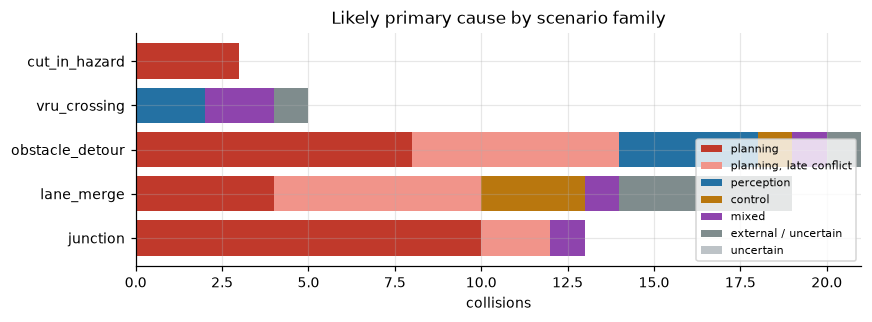

In [4]:
fams = ["junction", "lane_merge", "obstacle_detour", "vru_crossing", "cut_in_hazard"]
mat = [{"family": f, **{k: sum(1 for r in rows if r["family"] == f and r["attribution"] == k) for k in order},
        "total": sum(1 for r in rows if r["family"] == f)} for f in fams]
table(mat)
sit = sorted({r["situation"] for r in rows})
table([{"situation": s, **{k: sum(1 for r in rows if r["situation"] == s and r["attribution"] == k) for k in order}} for s in sit])

fig, ax = plt.subplots(figsize=(8, 3))
left = np.zeros(len(fams))
for k, c in zip(order, ["#c0392b", "#f1948a", "#2471a3", "#b9770e", "#8e44ad", "#7f8c8d", "#bdc3c7"]):
    v = np.array([m[k] for m in mat]); ax.barh(fams, v, left=left, color=c, label=k); left += v
ax.set_xlabel("collisions"); ax.legend(fontsize=7, loc="lower right"); ax.set_title("Likely primary cause by scenario family")
plt.tight_layout(); plt.savefig(FIG / "E_attribution.png", bbox_inches="tight"); plt.show()

## 4. Every collision with its evidence

Saved as `results/bench2drive_v2/pce/failure_attribution.csv`. Review the **low-confidence** rows by watching the recordings.

In [5]:
cols = ["route", "scenario", "situation", "other", "ego speed", "boxed share", "plan conflict onset (s)", "conflict from own boxes (s)", "max cross-track (m)",
        "attribution", "confidence", "evidence"]
out = sorted(rows, key=lambda r: (order.index(r["attribution"]), r["family"], r["route"]))
save_csv("failure_attribution", [{c: r[c] for c in cols} for r in out])
table(out, cols, fmt={"boxed share": pct})

| route | scenario | situation | other | ego speed | boxed share | plan conflict onset (s) | conflict from own boxes (s) | max cross-track (m) | attribution | confidence | evidence |
|---|---|---|---|---|---|---|---|---|---|---|---|
| 24781 | HardBreakRoute | rear-end (lead vehicle) | vehicle.mercedes | 5.90 | 100% | 1.50 | 1.10 | 0.05 | planning | high | actor boxed, conflict visible 1.5 s ahead, car followed the plan |
| 25358 | StaticCutIn | rear-end (lead vehicle) | vehicle.ford | 3.20 | 100% | 0.50 | 1.60 | 0.03 | planning | medium | actor boxed, conflict visible 1.6 s ahead, car followed the plan |
| 26396 | StaticCutIn | rear-end (lead vehicle) | vehicle.audi | 9.40 | 100% | 1.50 | 1.40 | 0.11 | planning | high | actor boxed, conflict visible 1.5 s ahead, car followed the plan |
| 2050 | SignalizedJunctionRightTurn | junction turn / crossing | vehicle.audi | 10.20 | 100% | 2.00 | 2.55 | 0.47 | planning | high | actor boxed, conflict visible 2.6 s ahead, car followed the plan |
| 2084 | NonSignalizedJunctionLeftTurn | junction turn / crossing | vehicle.audi | 10.50 | 100% | 0.50 | 1.25 | 0.38 | planning | medium | actor boxed, conflict visible 1.2 s ahead, car followed the plan |
| 2091 | NonSignalizedJunctionLeftTurn | junction turn / crossing | vehicle.audi | 5.10 | 100% | 2.00 | 1.85 | 0.37 | planning | high | actor boxed, conflict visible 2.0 s ahead, car followed the plan |
| 26990 | NonSignalizedJunctionLeftTurn | junction turn / crossing | vehicle.mercedes | 10.20 | 100% | 0.00 | 1.05 | 0.15 | planning | medium | actor boxed, conflict visible 1.1 s ahead, car followed the plan |
| 2881 | NonSignalizedJunctionLeftTurn | junction turn / crossing | vehicle.chevrolet | 10.40 | 100% | 0.50 | 1.60 | 0.27 | planning | medium | actor boxed, conflict visible 1.6 s ahead, car followed the plan |
| 3670 | NonSignalizedJunctionRightTurn | junction turn / crossing | vehicle.ford | 9.70 | 100% | 3.00 | 1.50 | 0.51 | planning | medium | actor boxed, conflict visible 3.0 s ahead, car followed the plan |
| 3936 | SignalizedJunctionLeftTurn | junction turn / crossing | vehicle.dodge | 8.90 | 100% | 1.00 | 1.45 | 0.24 | planning | high | actor boxed, conflict visible 1.5 s ahead, car followed the plan |
| 4468 | SignalizedJunctionLeftTurn | junction turn / crossing | vehicle.ford | 10.50 | 100% | 0.50 | 1.45 | 0.31 | planning | medium | actor boxed, conflict visible 1.5 s ahead, car followed the plan |
| 4669 | SignalizedJunctionLeftTurn | junction turn / crossing | vehicle.nissan | 10.40 | 100% | 0.50 | 1.45 | 0.30 | planning | medium | actor boxed, conflict visible 1.5 s ahead, car followed the plan |
| 4683 | SignalizedJunctionLeftTurn | junction turn / crossing | vehicle.audi | 9.80 | 100% | 1.00 | 1.50 | 0.34 | planning | high | actor boxed, conflict visible 1.5 s ahead, car followed the plan |
| 11755 | EnterActorFlow | junction turn / crossing | vehicle.nissan | 9.70 | 100% | 1.00 | 1.25 | 0.01 | planning | high | actor boxed, conflict visible 1.2 s ahead, car followed the plan |
| 23659 | HighwayExit | merge / exit | vehicle.dodge | 4.30 | 100% | 3.00 | 2.35 | 0.15 | planning | high | actor boxed, conflict visible 3.0 s ahead, car followed the plan |
| 23918 | InterurbanActorFlow | junction turn / crossing | vehicle.lincoln | 13.50 | 100% | 1.00 | 1.05 | 0.64 | planning | medium | actor boxed, conflict visible 1.1 s ahead, car followed the plan |
| 3785 | MergerIntoSlowTraffic | lane change | vehicle.dodge | 13.60 | 100% | 0.50 | 1.00 | 0.34 | planning | medium | actor boxed, conflict visible 1.0 s ahead, car followed the plan |
| 1790 | HazardAtSideLane | obstacle bypass | vehicle.ford | 9.80 | 100% | 3.00 | 2.05 | 0.24 | planning | high | actor boxed, conflict visible 3.0 s ahead, car followed the plan |
| 1825 | ConstructionObstacleTwoWays | obstacle bypass | vehicle.chevrolet | 11.10 | 100% | 0.50 | 1.80 | 0.23 | planning | medium | actor boxed, conflict visible 1.8 s ahead, car followed the plan |
| 2509 | ConstructionObstacle | obstacle bypass | vehicle.audi | 10.80 | 100% | 0.50 | 1.00 | 0.51 | planning | medium | actor boxed, conflict visible 1.0 s ahead, car followed the plan |
| 25383 | ParkedObstacle | obstacle bypass | vehicle.nissan | 10.10 | 100% | 0.50 | 1.00 | 0.35 | planning | medium | actor boxed, conflict visible 1.0 s ahead, car followed the plan |
| 25424 | ConstructionObstacleTwoWays | obstacle bypass | vehicle.chevrolet | 13.50 | 90% | 1.50 | 1.45 | 0.60 | planning | medium | actor boxed, conflict visible 1.5 s ahead, car followed the plan |
| 25857 | AccidentTwoWays | obstacle bypass | vehicle.mini | 12.70 | 100% | 3.00 | 0.75 | 0.53 | planning | medium | actor boxed, conflict visible 3.0 s ahead, car followed the plan |
| 2643 | AccidentTwoWays | obstacle bypass | vehicle.nissan | 11.00 | 100% | 2.00 | 2.00 | 0.15 | planning | high | actor boxed, conflict visible 2.0 s ahead, car followed the plan |
| 2664 | ParkedObstacleTwoWays | obstacle bypass | vehicle.dodge | 9.80 | 100% | 1.00 | 0.00 | 0.42 | planning | medium | actor boxed, conflict visible 1.0 s ahead, car followed the plan |
| 26956 | SignalizedJunctionRightTurn | junction turn / crossing | vehicle.mercedes | 12.00 | 100% | 0.50 | 0.95 | 0.37 | planning, late conflict | low | actor boxed, car followed its plans, conflict visible only 1.0 s ahead |
| 27018 | SignalizedJunctionRightTurn | other vehicle conflict | vehicle.dodge | 8.50 | 100% | 0.50 | 0.45 | 0.25 | planning, late conflict | low | actor boxed, car followed its plans, conflict visible only 0.5 s ahead |
| 23670 | HighwayExit | junction turn / crossing | vehicle.dodge | 11.40 | 100% | 0.50 | 0.65 | 0.65 | planning, late conflict | low | actor boxed, car followed its plans, conflict visible only 0.7 s ahead |
| 23687 | HighwayExit | junction turn / crossing | vehicle.mercedes | 11.70 | 86% | 0.50 | 0.60 | 0.68 | planning, late conflict | low | actor boxed, car followed its plans, conflict visible only 0.6 s ahead |
| 23901 | InterurbanActorFlow | static object | static | 11.50 | nan | 0.00 | 0.00 | 0.46 | planning, late conflict | low | actor boxed, car followed its plans, conflict visible only 0.0 s ahead |
| 24092 | MergerIntoSlowTrafficV2 | junction turn / crossing | vehicle.lincoln | 17.80 | 100% | 0.50 | 0.50 | 0.69 | planning, late conflict | low | actor boxed, car followed its plans, conflict visible only 0.5 s ahead |
| 3048 | MergerIntoSlowTraffic | lane change | vehicle.lincoln | 8.40 | 100% | 0.50 | 0.90 | 0.65 | planning, late conflict | low | actor boxed, car followed its plans, conflict visible only 0.9 s ahead |
| 3800 | MergerIntoSlowTraffic | lane change | vehicle.lincoln | 14.90 | 100% | 0.50 | 0.60 | 0.63 | planning, late conflict | low | actor boxed, car followed its plans, conflict visible only 0.6 s ahead |
| 1852 | AccidentTwoWays | obstacle bypass | vehicle.dodge | 12.30 | 100% | 0.50 | 0.50 | 0.52 | planning, late conflict | low | actor boxed, car followed its plans, conflict visible only 0.5 s ahead |
| 24795 | ConstructionObstacle | obstacle bypass | vehicle.dodge | 8.60 | 100% | 0.50 | 0.80 | 0.83 | planning, late conflict | low | actor boxed, car followed its plans, conflict visible only 0.8 s ahead |
| 2534 | Accident | obstacle bypass | vehicle.ford | 16.10 | 100% | 0.50 | 0.90 | 0.54 | planning, late conflict | low | actor boxed, car followed its plans, conflict visible only 0.9 s ahead |
| 25439 | HazardAtSideLane | obstacle bypass | vehicle.nissan | 7.20 | 100% | 0.50 | 0.80 | 0.48 | planning, late conflict | low | actor boxed, car followed its plans, conflict visible only 0.8 s ahead |
| 2802 | InvadingTurn | obstacle bypass | vehicle.audi | 9.70 | 100% | 0.00 | 0.45 | 0.53 | planning, late conflict | low | actor boxed, car followed its plans, conflict visible only 0.5 s ahead |
| 3472 | VehicleOpensDoorTwoWays | obstacle bypass | vehicle.dodge | 7.20 | 100% | 0.00 | 0.00 | 0.02 | planning, late conflict | low | actor boxed, car followed its plans, conflict visible only 0.0 s ahead |
| 1833 | ConstructionObstacleTwoWays | static object | static | 12.00 | 0% | 0.50 | 0.00 | 0.70 | perception | high | static object never boxed (TF++ has no class for it) |
| 20920 | ConstructionObstacleTwoWays | static object | static | 13.30 | 0% | 0.00 | 0.00 | 0.32 | perception | high | static object never boxed (TF++ has no class for it) |
| 2606 | ConstructionObstacleTwoWays | static object | static | 11.20 | 0% | 1.00 | 0.00 | 0.96 | perception | high | static object never boxed (TF++ has no class for it) |
| 3564 | InvadingTurn | static object | static | 10.80 | 0% | 3.00 | 0.00 | 0.34 | perception | high | static object never boxed (TF++ has no class for it) |
| 24211 | DynamicObjectCrossing | pedestrian / cyclist | walker.pedestrian | 14.00 | 5% | 2.00 | 0.00 | 0.03 | perception | high | actor boxed only 5% of the decision window |
| 24224 | DynamicObjectCrossing | pedestrian / cyclist | walker.pedestrian | 16.00 | 29% | 2.00 | 0.35 | 0.03 | perception | medium | actor boxed only 29% of the decision window |
| 17569 | SequentialLaneChange | lane change | vehicle.mercedes | 16.50 | 100% | 0.50 | 0.45 | 1.50 | control | low | car left its plan by 1.5 m before any conflict was visible (lane change at speed: some lag is normal) |
| 17655 | SequentialLaneChange | lane change | vehicle.ford | 17.50 | 100% | 0.50 | 0.60 | 1.10 | control | low | car left its plan by 1.1 m before any conflict was visible (lane change at speed: some lag is normal) |
| 2283 | MergerIntoSlowTraffic | lane change | vehicle.dodge | 15.60 | 100% | 0.50 | 0.70 | 1.02 | control | low | car left its plan by 1.0 m before any conflict was visible (lane change at speed: some lag is normal) |
| 1792 | HazardAtSideLane | obstacle bypass | vehicle.audi | 18.70 | 100% | 0.50 | 0.90 | 1.19 | control | medium | car left its plan by 1.2 m before any conflict was visible |
| 26950 | OppositeVehicleRunningRedLight | junction turn / crossing | vehicle.dodge | 11.30 | 62% | 1.00 | 0.00 | 0.45 | mixed | medium | conflict visible, but actor boxed only 62% |
| 17569 | SequentialLaneChange | lane change | vehicle.audi | 14.90 | 100% | 1.50 | 0.80 | 1.21 | mixed | medium | conflict visible, but car also left its plan by 1.2 m |
| 3482 | VehicleOpensDoorTwoWays | obstacle bypass | vehicle.chevrolet | 19.10 | 100% | 1.00 | 2.30 | 2.71 | mixed | medium | conflict visible, but car also left its plan by 2.7 m |
| 24206 | ParkingCrossingPedestrian | pedestrian / cyclist | walker.pedestrian | 10.90 | 62% | 1.50 | 0.95 | 0.34 | mixed | medium | conflict visible, but actor boxed only 62% |
| 3731 | VehicleTurningRoutePedestrian | pedestrian / cyclist | walker.pedestrian | 7.60 | 57% | 1.50 | 0.00 | 0.53 | mixed | medium | conflict visible, but actor boxed only 57% |
| 2201 | EnterActorFlow | struck while stopped / from behind | vehicle.mercedes | 10.30 | 100% | 2.00 | 1.45 | 0.38 | external / uncertain | medium | ego stopped or hit from behind |
| 23659 | HighwayExit | struck while stopped / from behind | vehicle.dodge | 0.00 | 100% | 3.00 | 0.00 | nan | external / uncertain | high | ego stopped or hit from behind |
| 23771 | MergerIntoSlowTrafficV2 | struck while stopped / from behind | vehicle.mercedes | 0.60 | 100% | 0.50 | 1.05 | 0.08 | external / uncertain | medium | ego stopped or hit from behind |
| 23901 | InterurbanActorFlow | static object | static | 0.00 | nan | 0.00 | 0.00 | nan | external / uncertain | high | ego stopped or hit from behind |
| 23901 | InterurbanActorFlow | static object | static | 0.00 | nan | 0.00 | 0.00 | nan | external / uncertain | high | ego stopped or hit from behind |
| 25439 | HazardAtSideLane | struck while stopped / from behind | vehicle.nissan | 0.00 | 100% | 3.00 | 2.35 | nan | external / uncertain | high | ego stopped or hit from behind |
| 3255 | ParkingCrossingPedestrian | pedestrian / cyclist | walker.pedestrian | 0.40 | 100% | 3.00 | 0.00 | 0.00 | external / uncertain | high | ego stopped or hit from behind |

## 5. Case studies

The three pictures below show one collision for each of the most common causes. Each is drawn from above, 1.5 s before impact:

- **Ego:** the black box at the origin, with **TF++'s planned path** as red dots, timed at its target speed.
- **TF++'s boxes** at that moment: blue outlines.
- **The struck actor:** its actual future path from ground truth as a green line, with its position at impact marked by an ×.

The right-hand panels show target speed, actual speed and braking over the last 3 s.

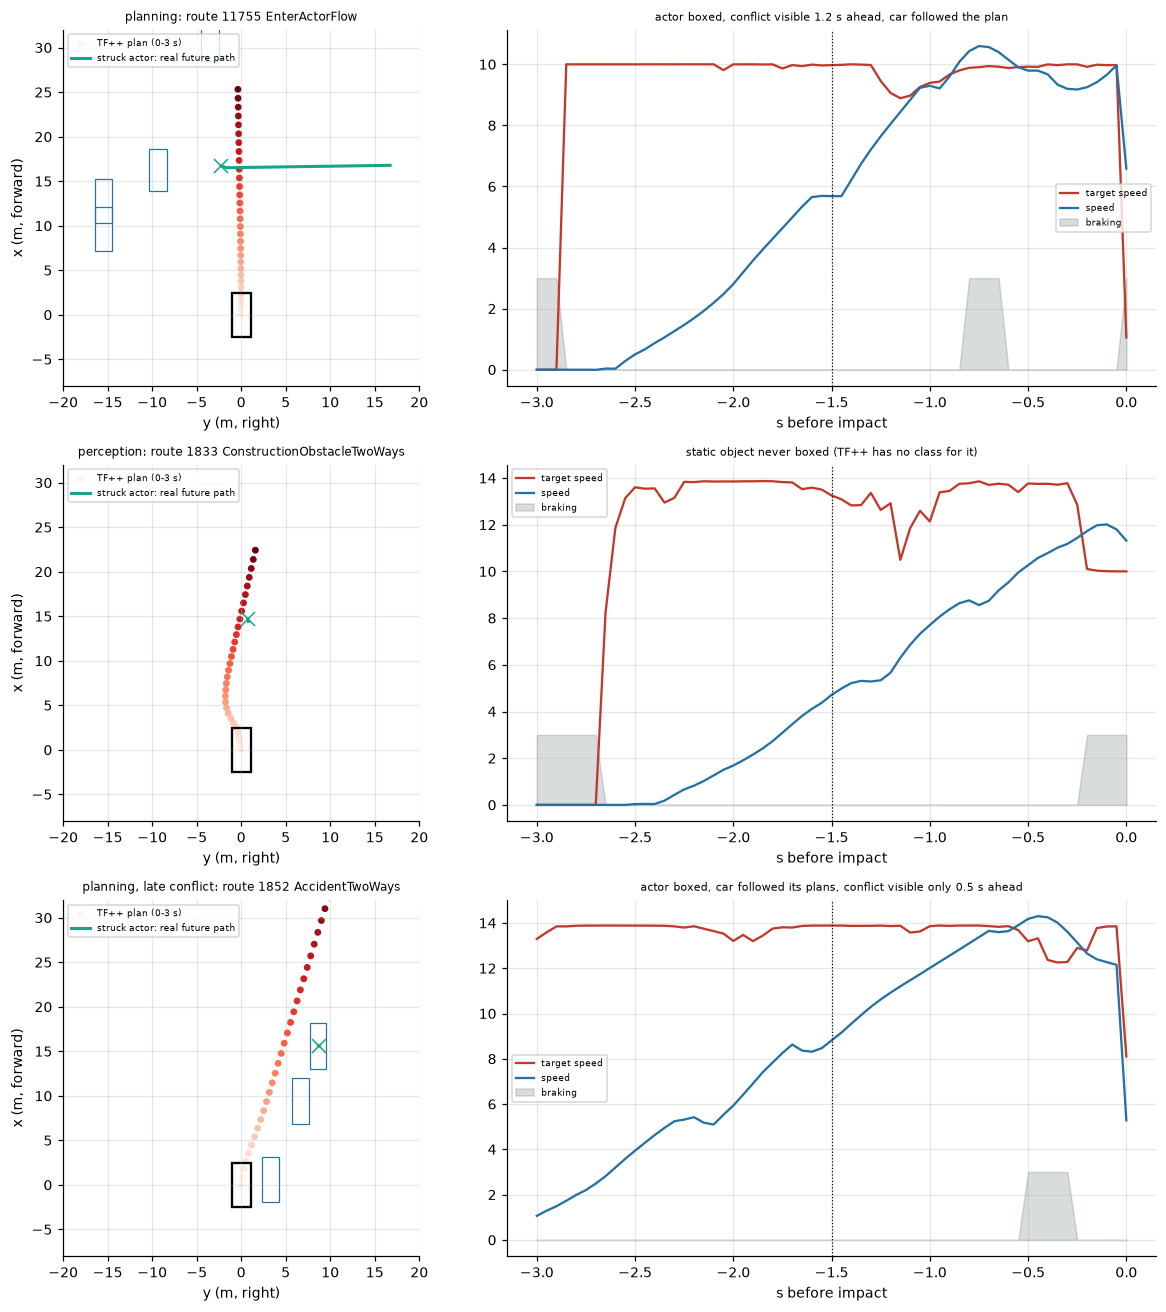

In [6]:
def draw_case(r, ax_map, ax_ts):
    e = next(x for x in crashes if x["route"] == r["route"] and x["scenario"] == r["scenario"])
    d = PC[e["route"]]; s = e["step"]; t = s - 30; ev = d["events"][e["event"]]; wt = ev["world_track"]
    ex, ey, _ = ew.plan_rollout(d["path"][t], d["speed"][t], d["tss"][t], ew.TAU)
    ax_map.scatter(ey, ex, c=ew.TAU, cmap="Reds", s=12, label="TF++ plan (0-3 s)")
    ax_map.add_patch(plt.Rectangle((-1.06, -2.45), 2.12, 4.9, fill=False, color="k", lw=1.5))
    if PERC is not None:
        B = PERC[e["route"]]["box"]; m = B["step"] == t
        for bx, by, bex, bey in zip(B["x"][m], B["y"][m], B["ext_x"][m], B["ext_y"][m]):
            ax_map.add_patch(plt.Rectangle((by - bey, bx - bex), 2 * bey, 2 * bex, fill=False, color="#2471a3", lw=0.8))
    sel = [i for i, st in enumerate(wt["step"]) if t <= st <= s and wt["present"][i]]
    if sel:
        P = np.array([pce.world_to_ego(d, t, wt["wx"][i], wt["wy"][i]) for i in sel])
        ax_map.plot(P[:, 1], P[:, 0], color="#17a589", lw=2, label="struck actor: real future path")
        ax_map.plot(P[-1, 1], P[-1, 0], "x", color="#17a589", ms=9)
    ax_map.set_xlim(-20, 20); ax_map.set_ylim(-8, 32); ax_map.set_aspect("equal")
    ax_map.set_xlabel("y (m, right)"); ax_map.set_ylabel("x (m, forward)")
    ax_map.set_title(f"{r['attribution']}: route {r['route']} {r['scenario']}", fontsize=8); ax_map.legend(fontsize=6, loc="upper left")
    tt = np.arange(-60, 1) * ew.DT
    ax_ts.plot(tt, d["tss"][s - 60:s + 1], color="#c0392b", label="target speed")
    ax_ts.plot(tt, d["speed"][s - 60:s + 1], color="#2471a3", label="speed")
    ax_ts.fill_between(tt, 0, d["brk"][s - 60:s + 1] * 3, color="#7f8c8d", alpha=0.3, label="braking")
    ax_ts.axvline(-1.5, color="k", ls=":", lw=0.8); ax_ts.set_xlabel("s before impact"); ax_ts.legend(fontsize=6)
    ax_ts.set_title(r["evidence"][:80], fontsize=7)

cases = []
for k in ("planning", "perception", "planning, late conflict"):
    c = [r for r in rows if r["attribution"] == k]
    c.sort(key=lambda r: (r["confidence"] != "high", r["route"]))
    if c:
        cases.append(c[0])
fig, axes = plt.subplots(len(cases), 2, figsize=(11, 4 * len(cases)), gridspec_kw={"width_ratios": [1, 1.3]})
axes = np.atleast_2d(axes)
for r, (a1, a2) in zip(cases, axes):
    draw_case(r, a1, a2)
plt.tight_layout(); plt.savefig(FIG / "E_case_studies.png", bbox_inches="tight"); plt.show()

## Takeaways

| Likely primary cause | Collisions | Share | High confidence | What it looks like |
|---|---|---|---|---|
| **Planning** | 25 | 41% | 10 | Actor boxed, conflict visible ≥1 s ahead, car followed its plan |
| **Planning, late conflict** | 14 | 23% | 0 | Same, but the conflict was only visible in the last second (path horizon about 11 m) |
| **Perception** | 6 | 10% | 5 | 4 construction props that TF++ has no class for; 2 pedestrians boxed 5% and 29% of the time |
| **Control** | 4 | 7% | 0 | High-speed lane changes and one bypass where the car lagged more than 1 m behind its plan |
| **Mixed** | 5 | 8% | 0 | Plan in conflict, plus partial perception (2 pedestrians, 1 emergency vehicle) or drift from the plan (2) |
| **External / uncertain** | 7 | 11% | 5 | Ego stopped or hit from behind; terrain contacts while stopped |

1. **Planning dominates**, at 64% including the late-conflict cases. Junction turns are 12 of 13 planning; obstacle detours 14 of 21; merges 10 of 19.
2. **Perception matters in specific places**: construction props (by design, there is no box class for them) and pedestrians. It does not explain vehicle crashes.
3. **Control is a minor contributor**, limited to tracking lag in high-speed lane changes. It is never high confidence.
4. **What it means for the monitor.** The failure to catch is a *confident commitment*: a stable plan, accelerating, with a conflict visible in TF++'s own plan and boxes about 1 s ahead in roughly half the cases. That points to intent-aware geometry (plan + tracked boxes) plus target-speed behaviour as the monitor's core signals, rather than planner instability.

**Caveats**

- These are rule-based attributions from logs, **not causal proof**. Thresholds (50% / 80% boxed, 1 s conflict, 1 m drift) are judgement calls.
- The 14 "late conflict" cases and the medium-confidence cases should be checked by watching the recordings.
- One seed, and 61 collisions.
- The hindsight plan check is limited by TF++'s short (about 11 m) path.
